In [23]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u
from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
M_test=2e14*u.Msun
E_M_test = 0.5*1e14*u.Msun
e_M_test = 0.3*1e14*u.Msun
z_test = 0.15
L_test = 1e44*u.erg/u.s

In [3]:
# create class to compare to
nfw_ref = NFWProfile(z_test, M500=M_test, L500=L_test)

In [4]:
print(nfw_ref.c500)
print(nfw_ref.R500)
print(nfw_ref.rs)
print(nfw_ref.rho_s.to(1e15*u.Msun/u.Mpc**3))

3.742138765540648
0.8468364020893303 Mpc
0.22629743447447573 Mpc
1.7896992918544108 1e+15 solMass / Mpc3


In [24]:
cls_err = Cluster_werr(z_test,
                       M500=M_test,
                       L500=L_test,
                       M500_err_lo=e_M_test,
                       M500_err_hi=E_M_test)

3.742138765540648 (+0.07858491407635361, -0.04715094844581216)
0.846836402089333 (+0.07056970017411107, -0.042341820104466646)
0.22629743447447645 (+0.019072463294701927, -0.012272333329365519)
1789699291854410.8 (+120587967378018.3, -77746869278855.25)


In [25]:
cls_err.M500

In [26]:
xs = np.logspace(-2,1)
rs_ref = xs*nfw_ref.R500
rs_err = xs*cls_err.R500


In [27]:
print(nfw_ref.P500_planelles())
print(cls_err.P500_planelles())

9.006118986012344e-12 erg / cm3
9.006118986012344e-12 ± 1.5010198310020572e-12


In [28]:
P500 = cls_err.P500_planelles()
print(P500)
P500

9.006118986012344e-12 ± 1.5010198310020572e-12


Text(0, 0.5, 'Pg (erg/cm3)')

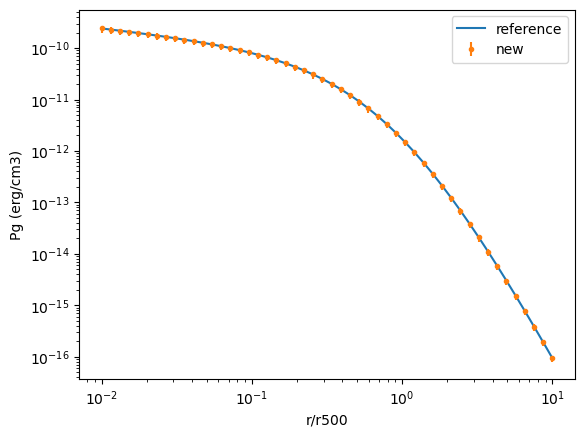

In [37]:
plt.loglog(xs, nfw_ref.Pg(xs), label='reference')
plt.errorbar(xs,
           [p.value for p in cls_err.Pg(xs)],
           yerr=[[p.plus for p in cls_err.Pg(xs)], [p.minus for p in cls_err.Pg(xs)]], fmt='o',markersize=3,
           label='new')

plt.legend()
plt.xlabel('r/r500')
plt.ylabel('Pg (erg/cm3)')

Text(0.5, 0, 'r (Mpc)')

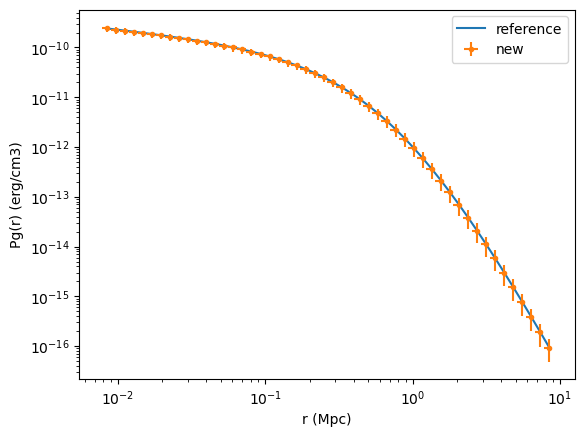

In [45]:
plt.loglog(rs_ref, nfw_ref.Pg_r(rs_ref), label='reference')
plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.Pg_r(rs_err)],
             yerr=[[p.plus for p in cls_err.Pg_r(rs_err)], [p.minus for p in cls_err.Pg_r(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')


plt.legend()
plt.ylabel('Pg(r) (erg/cm3)')
plt.xlabel('r (Mpc)')

In [55]:
cls_err.dP_dr(rs_err)

Text(0.5, 0, 'r (Mpc)')

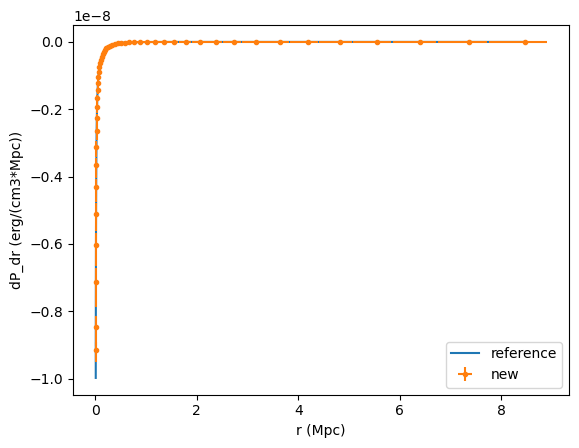

In [56]:
plt.plot(rs_ref, nfw_ref.dP_dr(rs_ref), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.dP_dr(rs_err)],
             yerr=[[p.plus for p in cls_err.dP_dr(rs_err)], [p.minus for p in cls_err.dP_dr(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')


plt.legend()
plt.ylabel('dP_dr (erg/(cm3*Mpc))')
plt.xlabel('r (Mpc)')

Text(0.5, 0, 'r (Mpc)')

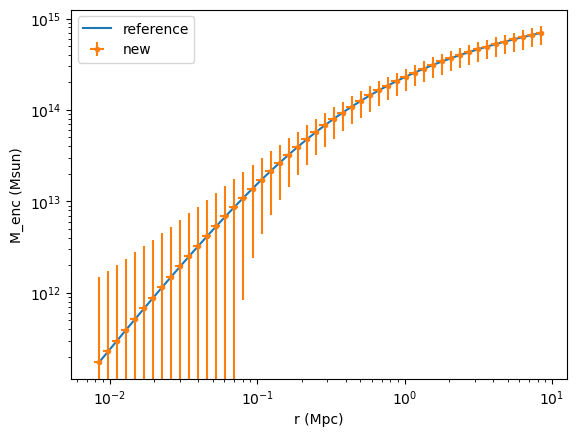

In [88]:
plt.loglog(rs_ref, nfw_ref.M_enc(rs_ref), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.M_enc(rs_err)],
             yerr=[[p.plus for p in cls_err.M_enc(rs_err)], [p.minus for p in cls_err.M_enc(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('M_enc (Msun)')
plt.xlabel('r (Mpc)')

Text(0.5, 0, 'r (Mpc)')

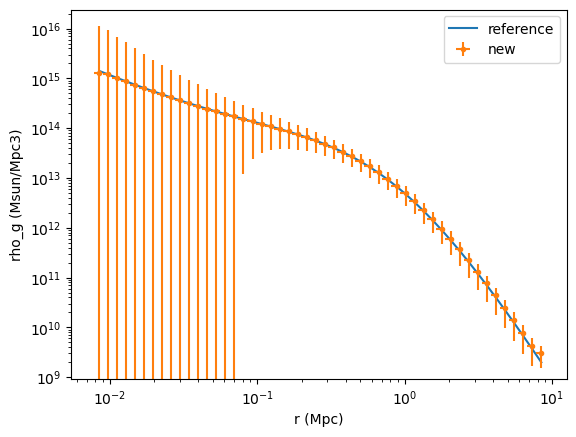

In [90]:
plt.loglog(rs_ref, nfw_ref.rho_g(rs_ref), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.rho_g(rs_err)],
             yerr=[[p.plus for p in cls_err.rho_g(rs_err)], [p.minus for p in cls_err.rho_g(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('rho_g (Msun/Mpc3)')
plt.xlabel('r (Mpc)')

In [73]:
from astropy import constants as const
const.G.to(u.Mpc**3 / (u.Msun*u.s**2))

<Quantity 4.51710305e-48 Mpc3 / (s2 solMass)>

In [77]:
const.G


<<class 'astropy.constants.codata2018.CODATA2018'> name='Gravitational constant' value=6.6743e-11 uncertainty=1.5e-15 unit='m3 / (kg s2)' reference='CODATA 2018'>

In [85]:
(u.erg/u.cm**3).to(u.Msun/u.Mpc**3)

1.6440094872954792e+19

In [ ]:
(u.erg/u.cm3)

Text(0.5, 0, 'r (Mpc)')

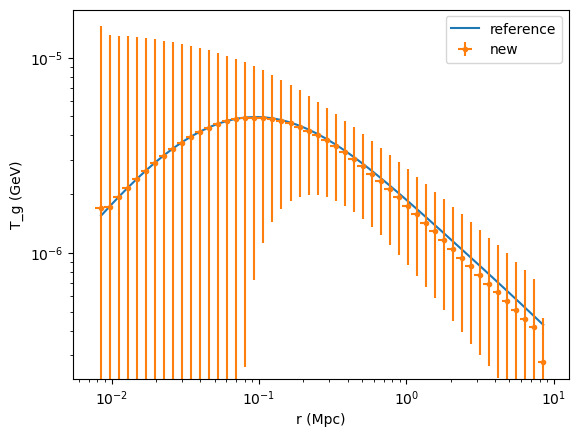

In [96]:
plt.loglog(rs_ref, nfw_ref.T_g([r.value for r in rs_ref]), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.T_g(rs_err)],
             yerr=[[p.plus for p in cls_err.T_g(rs_err)], [p.minus for p in cls_err.T_g(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('T_g (GeV)')
plt.xlabel('r (Mpc)')